# Cardiovascular Disease Analysis
**Goal:** Explore a dataset of patients record to undertand which factors are linked to Cardiovascular Disease.
**Workflow:** Data Cleaning -> Feature Engineering -> Exploratory Data Analysis    

# Loading the Libraries and Dataset

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("Cardio_Data.csv",sep=";")
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


# Basic Information

In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [48]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [49]:
df.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [50]:
df.shape

(70000, 13)

In [51]:
df[df.duplicated()].shape

(0, 13)

# Data Cleaning
1. changing age from numer of days to years

In [52]:
df['age'] = (df['age'] / 365).round().astype(int)
df

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,48,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,53,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,62,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,52,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,61,1,163,72.0,135,80,1,2,0,0,0,1


2. Converting genders to 'male' and 'female' from the codes 1 & 2 using average height of both the genders

In [53]:
avg_height = df.groupby('gender')['height'].mean()
m = avg_height.idxmax()
f = avg_height.idxmin()

df['gender_label'] = df['gender'].map({m: 'male', f: 'female'})
df

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,gender_label
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0,male
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1,female
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1,female
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1,male
4,4,48,1,156,56.0,100,60,1,1,0,0,0,0,female
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,53,2,168,76.0,120,80,1,1,1,0,1,0,male
69996,99995,62,1,158,126.0,140,90,2,2,0,0,1,1,female
69997,99996,52,2,183,105.0,180,90,3,1,0,1,0,1,male
69998,99998,61,1,163,72.0,135,80,1,2,0,0,0,1,female


In [54]:
df['gender'] = df['gender_label']
df = df.drop(columns='gender_label')
df

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,male,168,62.0,110,80,1,1,0,0,1,0
1,1,55,female,156,85.0,140,90,3,1,0,0,1,1
2,2,52,female,165,64.0,130,70,3,1,0,0,0,1
3,3,48,male,169,82.0,150,100,1,1,0,0,1,1
4,4,48,female,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,53,male,168,76.0,120,80,1,1,1,0,1,0
69996,99995,62,female,158,126.0,140,90,2,2,0,0,1,1
69997,99996,52,male,183,105.0,180,90,3,1,0,1,0,1
69998,99998,61,female,163,72.0,135,80,1,2,0,0,0,1


3. Changing the data of other rows from codes to string values for better understanding

In [55]:
cols = ["cholesterol", "gluc", "smoke", "alco", "active", "cardio","gender"]
df[cols] = df[cols].astype(object)

In [120]:
df = df.replace({
    "cholesterol": {1: "normal", 2: "high", 3: "extreme"},
    "gluc":        {1: "normal", 2: "high", 3: "extreme"},
    "smoke":       {0: "No", 1: "Yes"},
    "alco":        {0: "No", 1: "Yes"},
    "active":      {0: "No", 1: "Yes"},
    "cardio":      {0: "No", 1: "Yes"},
})
df

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,BMI,BMI_cat,age_group,bp_cat,BP
0,0,50,male,168,62.0,110,80,normal,normal,No,No,Yes,No,21.967120,Normal,40-50,Stage 1,30
1,1,55,female,156,85.0,140,90,extreme,normal,No,No,Yes,Yes,34.927679,Obese,50-60,Stage 2,50
2,2,52,female,165,64.0,130,70,extreme,normal,No,No,No,Yes,23.507805,Normal,50-60,Stage 1,60
3,3,48,male,169,82.0,150,100,normal,normal,No,No,Yes,Yes,28.710479,Overweight,40-50,Stage 2,50
4,4,48,female,156,56.0,100,60,normal,normal,No,No,No,No,23.011177,Normal,40-50,Normal,40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68562,99993,53,male,168,76.0,120,80,normal,normal,Yes,No,Yes,No,26.927438,Overweight,50-60,Stage 1,40
68563,99995,62,female,158,126.0,140,90,high,high,No,No,Yes,Yes,50.472681,Obese,60+,Stage 2,50
68564,99996,52,male,183,105.0,180,90,extreme,normal,No,Yes,No,Yes,31.353579,Obese,50-60,Hypertensive Crisis,90
68565,99998,61,female,163,72.0,135,80,normal,high,No,No,No,Yes,27.099251,Overweight,60+,Stage 1,55


4. Removing outliers blood pressure values

In [121]:
df = df[df['ap_hi'].between(70, 250) & df['ap_lo'].between(40, 150)]
df = df[df['ap_hi'] > df['ap_lo']]

5. Removing outliers height and weight values

In [122]:
df = df[df['height'].between(120, 210) & df['weight'].between(30, 200)]

6. Removing outliers BMI values

In [123]:
weight = df['weight'].astype(int)
height = (df['height']/100)**2
BMI = weight/height
df['BMI'] = BMI
df = df[df['BMI'].between(15, 60)].reset_index(drop=True)

In [124]:
records_dlt = 70000 - df.shape[0]
print(f"Total records cleaned are {records_dlt}")

Total records cleaned are 1433


# Feature Engineering
1. Categorising BMI

In [125]:
df['BMI_cat'] = pd.cut(df['BMI'], bins=[0, 18.5, 25, 30, 60], labels=['Underweight', 'Normal', 'Overweight', 'Obese'])
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,BMI,BMI_cat,age_group,bp_cat,BP
0,0,50,male,168,62.0,110,80,normal,normal,No,No,Yes,No,21.967120,Normal,40-50,Stage 1,30
1,1,55,female,156,85.0,140,90,extreme,normal,No,No,Yes,Yes,34.927679,Obese,50-60,Stage 2,50
2,2,52,female,165,64.0,130,70,extreme,normal,No,No,No,Yes,23.507805,Normal,50-60,Stage 1,60
3,3,48,male,169,82.0,150,100,normal,normal,No,No,Yes,Yes,28.710479,Overweight,40-50,Stage 2,50
4,4,48,female,156,56.0,100,60,normal,normal,No,No,No,No,23.011177,Normal,40-50,Normal,40


2. Categorising age

In [126]:
print(df['age'].max())
print(df['age'].min())

65
30


In [127]:
df['age_group'] = pd.cut(df['age'], bins=[29, 40, 50, 60, 70], labels=['30-40', '40-50', '50-60', '60+'])
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,BMI,BMI_cat,age_group,bp_cat,BP
0,0,50,male,168,62.0,110,80,normal,normal,No,No,Yes,No,21.967120,Normal,40-50,Stage 1,30
1,1,55,female,156,85.0,140,90,extreme,normal,No,No,Yes,Yes,34.927679,Obese,50-60,Stage 2,50
2,2,52,female,165,64.0,130,70,extreme,normal,No,No,No,Yes,23.507805,Normal,50-60,Stage 1,60
3,3,48,male,169,82.0,150,100,normal,normal,No,No,Yes,Yes,28.710479,Overweight,40-50,Stage 2,50
4,4,48,female,156,56.0,100,60,normal,normal,No,No,No,No,23.011177,Normal,40-50,Normal,40


3. Calculating Blood Pressure

In [128]:
df['BP'] = df['ap_hi'] - df['ap_lo']

4. Categorising Blood Pressure into groups

In [129]:
def bp_category(row):
    sys, dias = row['ap_hi'], row['ap_lo']
    if sys >= 180 or dias >= 120: return 'Hypertensive Crisis'
    if sys >= 140 or dias >= 90: return 'Stage 2'
    if sys >= 130 or dias >= 80: return 'Stage 1'
    if sys >= 120:            return 'Elevated'
    return 'Normal'

df['bp_cat'] = df.apply(bp_category, axis=1)
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,BMI,BMI_cat,age_group,bp_cat,BP
0,0,50,male,168,62.0,110,80,normal,normal,No,No,Yes,No,21.967120,Normal,40-50,Stage 1,30
1,1,55,female,156,85.0,140,90,extreme,normal,No,No,Yes,Yes,34.927679,Obese,50-60,Stage 2,50
2,2,52,female,165,64.0,130,70,extreme,normal,No,No,No,Yes,23.507805,Normal,50-60,Stage 1,60
3,3,48,male,169,82.0,150,100,normal,normal,No,No,Yes,Yes,28.710479,Overweight,40-50,Stage 2,50
4,4,48,female,156,56.0,100,60,normal,normal,No,No,No,No,23.011177,Normal,40-50,Normal,40


# Exploratory Data Analysis
1. Is the Data Balaced?

Text(0.5, 1.0, 'Cardiovascular Disease')

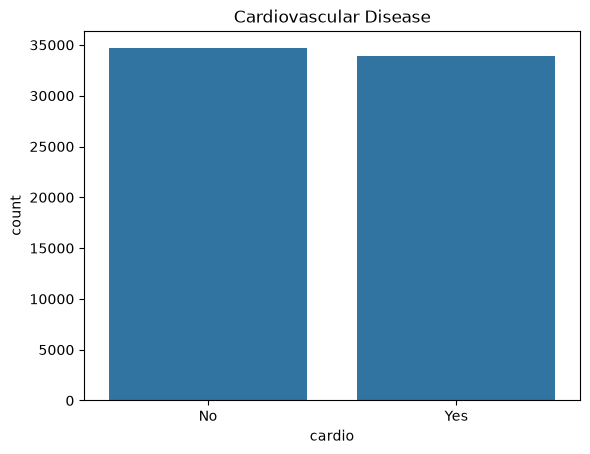

In [179]:
sns.countplot(x='cardio', data=df)
plt.title('Cardiovascular Disease')

2. Age Distribution by Disease

Text(0.5, 1.0, 'Age Distribution by Cardiovascular Disease')

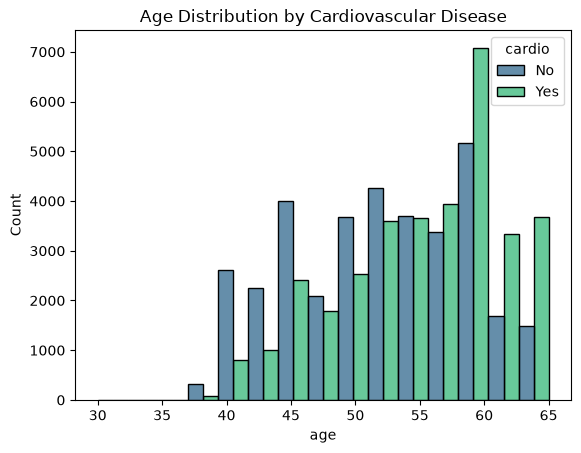

In [131]:
sns.histplot(data=df, x='age', hue='cardio', multiple='dodge', bins=15, palette='viridis')
plt.title('Age Distribution by Cardiovascular Disease')

3. Disease rate by age group

Text(0.5, 1.0, 'Rate of Deaseas by Age Group')

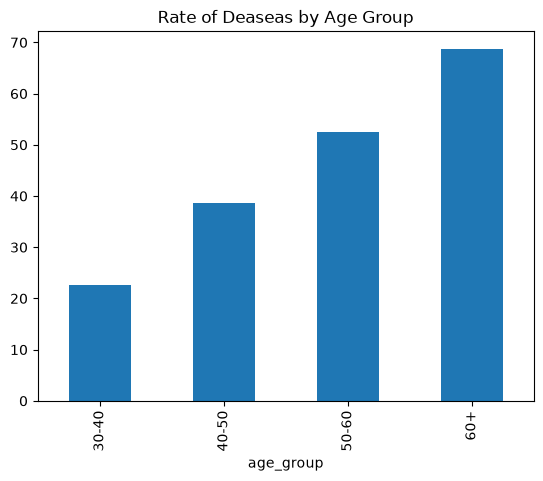

In [177]:
value = df[df['cardio'] == 'Yes'].groupby('age_group')['cardio'].count()
percentage = value/df.groupby('age_group')['cardio'].count()*100
percentage.plot(kind='bar')
plt.title("Rate of Deaseas by Age Group")

4. Disease rate by Gender

Text(0.5, 1.0, 'Rate of disease by Gender')

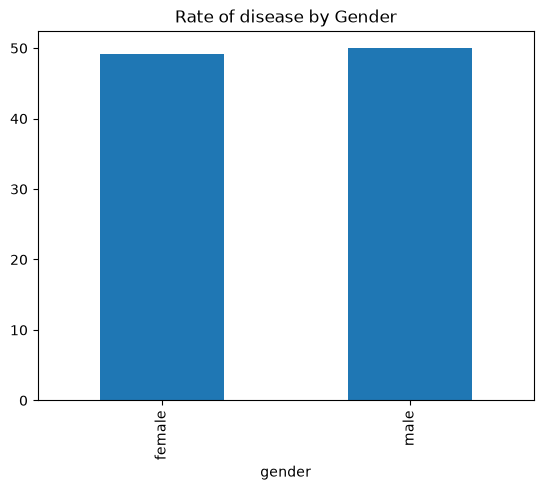

In [161]:
plt.xticks(rotation=45)
plt.title("Rate of disease by Gender")

5. Disease rate by BMI

Text(0.5, 1.0, 'Rate of disease by BMI')

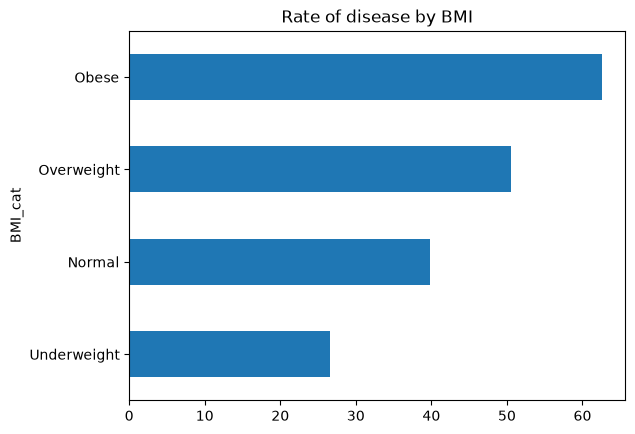

In [178]:
value = df[df['cardio'] == 'Yes'].groupby('BMI_cat')['cardio'].count()
percentage = value/df.groupby('BMI_cat')['cardio'].count()*100
percentage.sort_values(ascending = True).plot(kind='barh')
plt.title("Rate of disease by BMI")

5. Disease rate by BP Category

Text(0.5, 1.0, 'Rate of disease by BP Category')

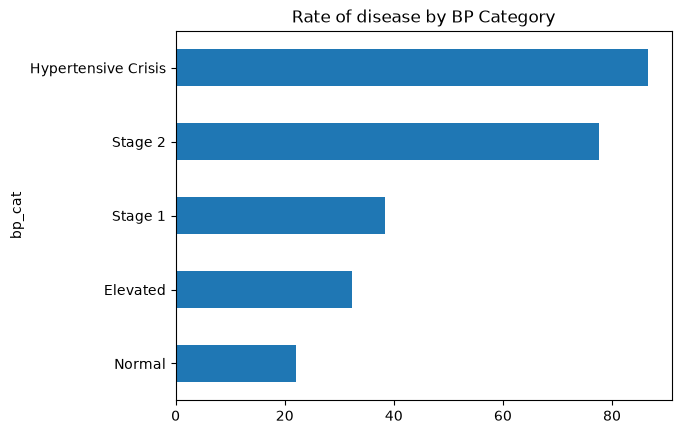

In [163]:
value = df[df['cardio'] == 'Yes'].groupby('bp_cat')['cardio'].count()
percentage = value/df.groupby('bp_cat')['cardio'].count()*100
percentage.sort_values(ascending = True).plot(kind='barh')
plt.title("Rate of disease by BP Category")

6. Disease rate by Cholestrol Level and Glucose Level

Text(0.5, 1.0, 'Disease rate by Cholestrole')

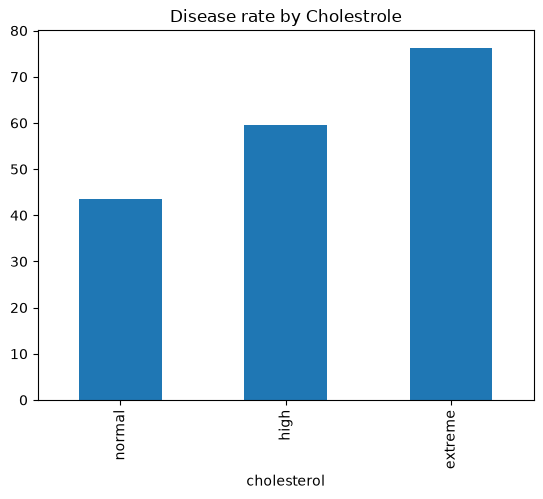

In [151]:
valueC = df[df['cardio'] == 'Yes'].groupby('cholesterol')['cardio'].count()
percentageC = valueC/df.groupby('cholesterol')['cardio'].count()*100
percentageC.sort_values(ascending = True).plot(kind='bar')
plt.title("Disease rate by Cholestrole")

Text(0.5, 1.0, 'Disease rate by Glucoase level')

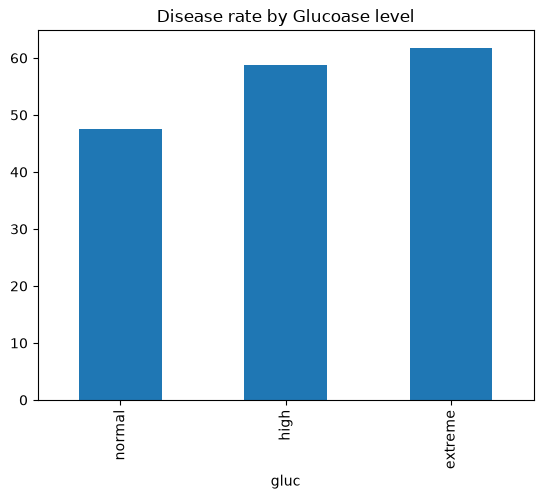

In [152]:
valueG = df[df['cardio'] == 'Yes'].groupby('gluc')['cardio'].count()
percentageG = valueG/df.groupby('gluc')['cardio'].count()*100
percentageG.sort_values(ascending = True).plot(kind='bar')
plt.title("Disease rate by Glucoase level")

7. Disease rate by Smoking, Alcohol and Physical Activity habits

Text(0.5, 1.0, 'Disease rate by Smoking Habits')

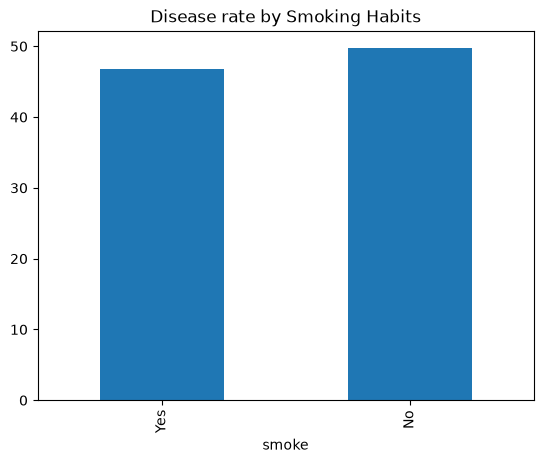

In [164]:
valueS = df[df['cardio'] == 'Yes'].groupby('smoke')['cardio'].count()
percentageS = valueS/df.groupby('smoke')['cardio'].count()*100
percentageS.sort_values(ascending = True).plot(kind='bar')
plt.title("Disease rate by Smoking Habits")

Text(0.5, 1.0, 'Disease rate by Alcohol Drinking Habit')

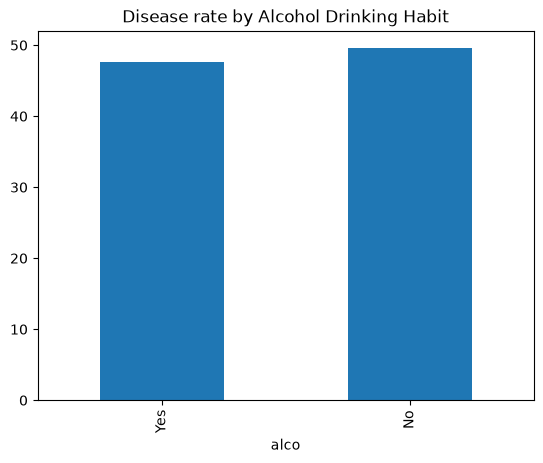

In [165]:
valueA = df[df['cardio'] == 'Yes'].groupby('alco')['cardio'].count()
percentageA = valueA/df.groupby('alco')['cardio'].count()*100
percentageA.sort_values(ascending = True).plot(kind='bar')
plt.title("Disease rate by Alcohol Drinking Habit")

Text(0.5, 1.0, 'Disease rate by Physical Activity Habit')

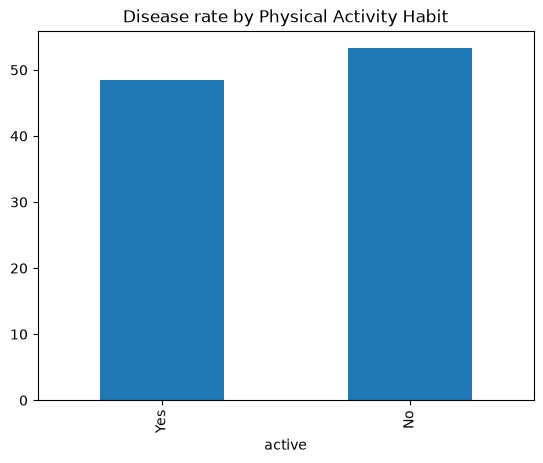

In [166]:
valuePA = df[df['cardio'] == 'Yes'].groupby('active')['cardio'].count()
percentagePA = valuePA/df.groupby('active')['cardio'].count()*100
percentagePA.sort_values(ascending = True).plot(kind='bar')
plt.title("Disease rate by Physical Activity Habit")